# Same Card Recognition (*SCR*) metric exploration

## 1. Introduction and motivations

### Introduction
The model we developed produces bounding boxes located on the **corner** of the card, over the rank and suit: this will result, for every card fully visibile, in two object detected of the same class (rank+suit).

#### Goal
In order to keep track of each (real) **card** we would like to be able to know wheter the detection of two same-class (rank+suit) objects belong to a same underlying physical card.

This is not a problem if the IS that uses our model works with a game played with a single deck of card. The problem arises whenever a game is played wuth two or more deck, in which cases the system must be able to distinguish how many physical cards have appeared in the frame.

We call *<u>S</u>ame <u>C</u>ard <u>R</u>ecognition* (*SCR*) the described problem.

#### Idea
Both the dimension of the bounding box and the relative position between boxes are related to the dimension of the card, and scale with the card relative size.
Hence we could try to derive a geometric relation between two bounding boxes of the same card, and compare it to the value of the same relation on a pair of bounding boxes belonging to different cards.

### Proposed metric (*Doa*)
For the Same-Card Recognition metric we chose the *distance* between two bounding boxes centers over the square root of the avreage of their areas:

Given a bounding box ${bb}_i$ we indicate with:
- $(x_i, y_i)$ the normalized coordinated of its center
- $A_i$ its normalized area 


Given a pair of bounding boxs ${bb}_1$ and ${bb}_2$ we can define:
- The distance ***d*** between the centers of the bounding boxes:
$$d = \sqrt{(x_1-x_2)^2 + (y_1-y_2)^2}$$ 
- The average of their areas ***avgA***:
$$\mathrm{avgA} = \frac{A_1 + A_2}{2}$$

We can finally define out metric ***m*** (*DoA* or *DoSAA*) as:
$$m = \frac{d}{\sqrt{\mathrm{avgA}}}$$

The complete metric can be written as:
$$m(\mathrm{bb}_1,\mathrm{bb}_2) =
\frac{\sqrt{(x_1-x_2)^2 + (y_1-y_2)^2}}
{\sqrt{\frac{A_1 + A_2}{2}}}$$

We call this metric *<u>D</u>istance <u>o</u>ver <u>A</u>rea* (*DoA*) / *<u>D</u>istance <u>o</u>ver <u>S</u>quared <u>A</u>rea <u>A</u>verage* (*DoSAA*)

### Approach

#### Goal
Given our chosen metric *DoA*, we want to extract some values (a range ideally) of our metric to be able to use such value in depplyment

#### Problem
From our datasets we do **not** have information wheter two bounding boxes of the same class in a given image belong to the same physical card. 

#### Solution
We could try to approximate this information considering that top-of-deck cards have all corners visibile, while occluded cards have only one corner visibile.

Under this approach, we treat *same-class* pairs as potential *same-card* pairs, excluding a limit case: we don't consider cases where three or more bounding boxes of the same class are recognized, as there is not way to pair the bounding boxes to their physical cards.

We highlight a probelm with this approach: there could an image with two same-class cards, both partially occluded; hence two bounding boxes of the same classe will be detected. Following our approach they will be considered as a same-card pair. 

We think that this does not influence our result in a significant manner, because there is guaranteed a top card for each image, while the number of same-class cards both partially occluded is far lower.

## 2. General Parameters

In [1]:
# Path of the dataset
from pathlib import Path

DATASET_NAME = 'pcd_merge_kfcv'
DATASET = Path('/workspace/datasets') / DATASET_NAME

In [2]:
# Path to chosen model
MODELS_DIR = Path('/workspace/models')

MODEL_PATH = MODELS_DIR / 'selected/best.pt'

In [3]:
OUTPUT_DIR = MODELS_DIR / 'selected'

## 3. Bounding box extraction

The goal of this stage is to extract geometric information from  all the possibile bounding boxes. We chose **not** to use the bounding box information provided by the dataset but to use the bounding boxes predicted by our chosen mode.

The reason is that the precise value of the metric depends on the precision of the bounding boxes (for example having 'large' bounding boxes will result in higher averga area, thus lower a *DoA* metric), and the precision of the model used in deployment could be different from the precision of the bounding boxes provided by the two datasets.

---

The process of this stage is:
- Load the selected model
- Perform predictions over all images at our disposal
  - Images are also scaled and shifted
- Select only the images without any false positives FP and false negative FN
- Save geometric information (center, dimensions) of all bounding boxes of these images

In [4]:
BBOX_RESULTS_FILENAME = 'complete_detections.json'

### 3.A Utility functions

#### 3.A.1 YOLO Import

In [5]:
# ===== YOLO Import
!apt-get update
!apt-get install -y libgl1
!apt-get install -y libglib2.0-0
!pip install -U ultralytics
!pip install pillow-heif

from ultralytics import YOLO

Get:1 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1581 B]
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [2816 kB]
Get:3 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]      
Hit:4 http://archive.ubuntu.com/ubuntu jammy InRelease                         
Get:5 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]        
Get:6 http://security.ubuntu.com/ubuntu jammy-security/main amd64 Packages [4089 kB]
Get:7 http://security.ubuntu.com/ubuntu jammy-security/universe amd64 Packages [1311 kB]
Get:8 http://archive.ubuntu.com/ubuntu jammy-backports InRelease [127 kB]     
Get:9 http://archive.ubuntu.com/ubuntu jammy-updates/main amd64 Packages [4425 kB]
Get:10 http://archive.ubuntu.com/ubuntu jammy-updates/universe amd64 Packages [1614 kB]
Fetched 14.6 MB in 2s (7277 kB/s)                          
Reading package lists... Done
Reading package lists... Done
Building depen

#### 3.A.2 Bounding box conversion functions

- `bbox_normalize` converts from / to *normalized* coordinates from / to *absolute* coordinates
- `bbox_convert`converts from / to *corner-based* coordinates (x1, y1, x2, y2) from / to *center-based* coordinates (xc, yc, w, h)

In [6]:
# ===== bbox_normalize
def _bbox_normalize_absolute_to_normalized(bbox, imgsize):
    H, W = imgsize

    return [
        bbox[0] / W,
        bbox[1] / H,
        bbox[2] / W,
        bbox[3] / H
    ]


def _bbox_normalize_normalized_to_absolute(bbox, imgsize):
    H, W = imgsize

    return [
        bbox[0] * W,
        bbox[1] * H,
        bbox[2] * W,
        bbox[3] * H
    ]

def bbox_normalize(bbox, imgsize, from_ = 'absolute', to_ = 'normalized'):
    
    if from_ == 'absolute' and to_ == 'normalized':
        return _bbox_normalize_absolute_to_normalized(bbox, imgsize)

    elif from_ == 'normalized' and to_ == 'absolute':
        return _bbox_normalize_normalized_to_absolute(bbox, imgsize)
    
    return bbox

In [7]:
# ===== bbox_convert
def _bbox_convert_corner_to_center(bbox):
    """
    Converts corner-based BBox [x1, y1, x2, y2]
    to center-based BBox [xc, yc, W, H]
    """
    xc = (bbox[2] + bbox[0]) / 2
    yc = (bbox[3] + bbox[1]) / 2
    
    w = bbox[2] - bbox[0]
    h = bbox[3] - bbox[1]

    return [xc, yc, w, h]

def _bbox_convert_center_to_corner(bbox):
    """
    Converts center-based BBox [xc, yc, W, H]
    to corner-based BBox [x1, y1, x2, y2]
    """
    x1 = bbox[0] - bbox[2] / 2
    x2 = bbox[0] + bbox[2] / 2
    
    y1 = bbox[1] - bbox[3] / 2
    y2 = bbox[1] + bbox[3] / 2

    return [x1, y1, x2, y2]
    
def bbox_convert(bbox, from_ = 'corner', to_ = 'center'):
    """
    Converts between
    - center-based BBox [xc, yc, W, H]
    - corner-based BBox [x1, y1, x2, y2]
    """

    if from_ == 'corner' and to_ == 'center':
        return _bbox_convert_corner_to_center(bbox)

    elif from_ == 'center' and to_ == 'corner':
        return _bbox_convert_center_to_corner(bbox)
    
    return bbox

#### 3.A.3 IoU functions
Function to calculate the *IoU* metric of two bounding boxes
- `iou_corner` calculates the *IoU* of two corner-based bounding boxes
- `iou_center` calculates the *IoU* of two center-based bounding boxes

In [ ]:
def iou_corner(bb_a, bb_b):
    xa1, ya1, xa2, ya2 = bb_a
    xb1, yb1, xb2, yb2 = bb_b

    # Intersection
    # Idea: take bigger x1,y1 coordinate, smaller x2,y2 coordinates 
    inter_x1, inter_y1 = max(xa1, xb1), max(ya1, yb1)
    inter_x2, inter_y2 = min(xa2, xb2), min(ya2, yb2)
    inter_w, inter_h = max(0.0, inter_x2 - inter_x1), max(0.0, inter_y2 - inter_y1)
    inter_area = inter_w * inter_h

    # Union
    area_a = (xa2 - xa1) * (ya2 - ya1)
    area_b = (xb2 - xb1) * (yb2 - yb1)
    union = area_a + area_b - inter_area

    # IoU
    return inter_area / union if union > 0 else 0.0

def iou_center(bb_a, bb_b):
    bb_a = bbox_convert(bb_a, from_ = 'center', to_ = 'corner')
    bb_b = bbox_convert(bb_b, from_ = 'center', to_ = 'corner')

    return iou_corner(bb_a, bb_b)

#### 3.A.4 Load labels
Load ground-truth labels from file. Also the bounding box coordinates are converted from normalized center-based to absolute corner-based. This is done to match the style of the output of the YOLO model.

In [9]:
# ===== load_labels function
def load_labels(label_path, imgsize):
    """ 
    Load labels from label file .txt

    Returns list(dict), where each bbox has the following structure:
    {
        "class_id": <cls_id>, 
        "box": [x1, y1, x2, y2] // abs coordinates
    }
    """
    
    bboxes = []
    if not Path(label_path).is_file():
        return bboxes

    # Open file content
    with open(label_path, "r") as f:

        # read each line (one line per bbox)
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.split()

            # first part = class index
            cls_id = int(parts[0])

            # other 4 parts = [xc, xy, W, H] normalized (force them to float)
            bb_norm_center = list(map(float, parts[1:5]))

            # Convert to corner based
            bb_norm_corner = bbox_convert(bb_norm_center, from_ = 'center', to_ = 'corner')

            # Convert to absolute coordinates
            bb_abso_corner = bbox_normalize(bb_norm_corner, imgsize, from_ = 'normalized', to_ = 'absolute')

            # Append class and corner-based, absolute coord
            bboxes.append(
                {
                    "class_id": cls_id, 
                    "box": bb_abso_corner
                }
            )
            
    return bboxes

#### 3.A.5 Image complete match
Function to check if each and all predicted bounding boxes are correctly matched with all ground-truth boundign boxes. The function returns true if there are no FP, no FN and if there was at least a bounding box in the image.

In [10]:
# ===== bbox_complete_match function
def bbox_complete_match(
    bboxes_gt, bboxes_pred,
    iou_thresh_match
):
    matched_pred_idx = set()
    matched_gt_idx = set()
    pred_order = sorted(range(len(bboxes_pred)), key=lambda i: -bboxes_pred[i]["conf"])

    # loop over each gt bbox
    for gt_i, gt in enumerate(bboxes_gt):

        # search for best match to current gt bbox
        best_iou, best_pred_idx = 0.0, -1

        # loop over all predictions
        for pred_idx in pred_order:

            # skip if pred bb has already matched
            if pred_idx in matched_pred_idx:
                continue
            pred = bboxes_pred[pred_idx]

            # skip if different class
            if pred["class_id"] != gt["class_id"]:
                continue

            # evaluate IoU
            iou = iou_corner(pred["box"], gt["box"])
            if iou > best_iou:
                best_iou, best_pred_idx = iou, pred_idx

        # add best match for current gt bb (if present)
        if best_pred_idx != -1 and best_iou >= iou_thresh_match:
            matched_pred_idx.add(best_pred_idx)
            matched_gt_idx.add(gt_i)

    n_gt = len(bboxes_gt)
    n_pred = len(bboxes_pred)
    fn = n_gt - len(matched_gt_idx)
    fp = n_pred - len(matched_pred_idx)

    # Return True if no FN and no FP (also if some objects where present)
    return (n_gt > 0) and (fn == 0) and (fp == 0)


#### 3.A.6 Image (and bounding box) zoom and shift
Zoom and shift randomly, within a given interval, the image and its relative ground-truth bounding boxes.

---

Given a random scale $s$, random shift in the x direction $t_x$ and random shift in the y direction $t_y$ we can define the tranformation matrix relative to the image center as:
$$
M = \begin{bmatrix} 
\textit{s} & 0 & (1 - \textit{s}) \cdot c_x + t_x \\ 
0 & \textit{s} & (1 - \textit{s}) \cdot c_y + t_y \\ 
0 & 0 & 1 
\end{bmatrix}
$$


In [11]:
import random
import cv2
import numpy as np

def random_zoom_shift(
    img,
    gt_bboxes,
    zoom_range=(0.8, 1.2),
    shift_range=0.1,
):
    """
    img: ndarray OpenCV
    gt_bboxes: list(dict) con struttura:
        {
            "class_id": int,
            "box": [x1, y1, x2, y2]
        }

    Returns
    -------
    img_aug
    gt_bboxes_aug
    """
    
    ### 1) Construct the transformation matrix

    h, w = img.shape[:2]

    # Random scaling factor
    scale = random.uniform(*zoom_range)

    # Random shift in each direction
    tx = random.uniform(-shift_range, shift_range) * w
    ty = random.uniform(-shift_range, shift_range) * h

    # all relative to the center of the image
    cx = w / 2
    cy = h / 2

    # Construct the transformation matrix
    M = np.array([
        [scale, 0, (1 - scale) * cx + tx],
        [0, scale, (1 - scale) * cy + ty]
    ], dtype=np.float32)

    ### 2) Tranform the image
    
    # Apply the transformation
    img_aug = cv2.warpAffine(
        img,
        M,
        (w, h),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(114, 114, 114),
    )
    
    ### 3) Transform the bounding boxes

    gt_bboxes_aug = []

    for bb in gt_bboxes:

        x1, y1, x2, y2 = bb["box"]

        # Construct the bb rectangle
        corners = np.array([
            [x1, y1],
            [x2, y1],
            [x2, y2],
            [x1, y2]
        ], dtype=np.float32).reshape(-1, 1, 2)

        # Apply the transformation to the rectangle
        corners = cv2.transform(corners, M).reshape(-1, 2)

        # Clip corners within borders
        xmin = np.clip(corners[:, 0].min(), 0, w)
        xmax = np.clip(corners[:, 0].max(), 0, w)
        ymin = np.clip(corners[:, 1].min(), 0, h)
        ymax = np.clip(corners[:, 1].max(), 0, h)

        # eliminate BB out of image after shift/zoom
        if xmax <= xmin or ymax <= ymin:
            continue

        gt_bboxes_aug.append({
            "class_id": bb["class_id"],
            "box": [float(xmin), float(ymin), float(xmax), float(ymax)]
        })

    return img_aug, gt_bboxes_aug

### 3.B Find complete image function

#### 3.B.1 Function definition
This function used all teh previous helper functions; it loads all images, makes predictions on each one and confronts the predicted bounding boxes to the ground-truth bounding boxes.

In [12]:
# ==== find_complete_images function definition
import cv2
import glob
import json
import csv
import random

def find_complete_images_zs(
    model_path: Path,
    dataset_dir: Path,
    output_dir: Path,
    max_images = None,
    device = "cpu",
    conf_thresh = 0.25,
    iou_thresh_match = 0.5,
    verbose = True,
):
    output_dir.mkdir(parents=True, exist_ok=True)

    image_folder = str(dataset_dir / 'images')
    label_folder = dataset_dir / 'labels'

    # Load model
    model = YOLO(str(model_path), task="detect")

    # Get and shuffle images, limit if specified
    images = sorted(glob.glob(f"{image_folder}/*.jpg"))
    
    random.shuffle(images)
    if max_images is not None:
        images = images[:max_images]

    if len(images) == 0:
        raise ValueError(f"Nessuna immagine trovata in {image_folder}")

    fully_detected = []


    # Loop over all images
    for img_path in images:

        img_path = Path(img_path)
        img = cv2.imread(str(img_path))
        imgsize = img.shape[:2]

        # Get corresponding label
        label_path = label_folder / (img_path.stem + ".txt")

        # load ground truth bboxes
        gt_bboxes = load_labels(label_path, imgsize)

        # random shift and zoom
        img_aug, gt_boxes_aug = random_zoom_shift(
            img,
            gt_bboxes
        )
        
        # Inference on image
        result = model.predict(img_aug, device=device, conf=conf_thresh, verbose=False)[0]

        # Fill predcited BBox list
        predicted_bb = []
        if result.boxes is not None and len(result.boxes) > 0:
            xyxy = result.boxes.xyxy.cpu().numpy()
            cls = result.boxes.cls.cpu().numpy().astype(int)
            conf = result.boxes.conf.cpu().numpy()
            for box, c, cf in zip(xyxy, cls, conf):
                box_norm = bbox_normalize(box.tolist(), imgsize, from_ = 'absolute', to_ = 'normalized')
                box_norm_center = bbox_convert(box_norm, from_ = 'corner', to_ = 'center')
                
                predicted_bb.append({
                    "class_id": int(c), 
                    "conf": float(cf), 
                    "box": box.tolist(),
                    "box_center_norm": box_norm_center
                })

        # Check if all BBoxes match
        image_match = bbox_complete_match(gt_boxes_aug, predicted_bb, iou_thresh_match)
        
        if image_match:
            fully_detected.append({
                "image_name": img_path.name,
                "image_path": str(img_path),
                "predicted_boxes": predicted_bb,
            })
            
    # Save to file
    out_json = output_dir / BBOX_RESULTS_FILENAME
    with open(out_json, "w") as f:
        json.dump(fully_detected, f, indent=2)

    if verbose:
        print(f"\nTotal images: {len(images)}")
        print(f"Images with all BB recognized: {len(fully_detected)}")
        print(f"Output saved to:\n  {out_json}")

    return fully_detected

#### 3.B.2 Function call

In [ ]:
_r = find_complete_images_zs(
    model_path=MODEL_PATH,
    dataset_dir=DATASET,
    output_dir=OUTPUT_DIR,
    device=0
)

## 4. Metric analysis

### 4.A Metric definition
As previously discussed, the chosen metric is:
$$m(\mathrm{bb}_1,\mathrm{bb}_2) =
\frac{d_{centers}}{\sqrt{\mathrm{avgA}}} =
\frac{\sqrt{(x_1-x_2)^2 + (y_1-y_2)^2}}
{\sqrt{\frac{A_1 + A_2}{2}}}$$

Were givien a bounding box ${bb}_i$ we indicate with:
- $(x_i, y_i)$ the normalized coordinated of its center
- $A_i$ its normalized area 


In [14]:
# Metric to evaluate
import numpy as np

def metric_DoA(bb1, bb2):
    """ 
        Evaluate DoA metric with center-based normalized BBoxes

    Parameters
    ----------
        bbox: list()
            bbox = [xc, yc, W, H]
    """

    # Distance between centers
    d = np.linalg.norm([bb1[0] - bb2[0], bb1[1] - bb2[1]])

    # Areas
    A1 = bb1[2] * bb1[3]
    A2 = bb2[2] * bb2[3] 

    # Square root of average of areas
    SSA = np.sqrt(0.5 * (A1 + A2))

    # return DoA
    return d / SSA

### 4.B Construct *pos* and *neg* lists
Construct two lists of metric values:
- `pos` is a list composed by metric values for same-card bounding box pairs
- `neg` is a list composed by metric values for different-card bounding box pairs

#### 4.B.1 Load bounding box list from file

In [15]:
# Load results from file
import json

def get_bbox_list(file: Path = OUTPUT_DIR / BBOX_RESULTS_FILENAME):

    with open(str(file), "r") as jsonfile: 
        data = json.load(jsonfile)
        return data
        
    return None

#### 4.B.2 Compute metric over list of pairs

In [16]:
# Function to compute scores of each pair of a list 
def compute_metric(pairs, metric):
    return [
        metric(a["box_center_norm"], b["box_center_norm"]) 
        for a, b in pairs
    ]

#### 4.B.3 Build pairs of BBoxes
Build two lists of pairs of bounding boxes:
- first list is composed of pairs of bounding boxes of the same class (*pos*)
- second list is composed of pairs of bounding boxes of different classs (*neg*)

In [17]:
# Build two lists of pairs of bounding boxes:
# - first list is composed of pairs of bounding boxes of the same class
# - second list iscomposed of pairs of bounding boxes of different class
from collections import defaultdict

def build_pairs(complete_detection_json):

    # Positivity: same class
    pos = []
    neg = []

    # loop over all images
    for img_results in complete_detection_json:

        # list of bb of the image
        bbs = img_results["predicted_boxes"]

        # group by image
        by_class = defaultdict(list)
        for bb in bbs:
            by_class[bb["class_id"]].append(bb)

        # positive pair: only if 2 boxes per class
        for group in by_class.values():
            if len(group) == 2:
                pos.append((group[0], group[1]))

        # negatives: every possible pair with different classes
        classes = list(by_class.keys())

        # double loop -> piar of distinct classes
        for i in range(len(classes)):
            for j in range(i + 1, len(classes)):

                # for each pair (Ci, Cj) we can cross 
                # all their bounding boxes
                for bb1 in by_class[classes[i]]:
                    for bb2 in by_class[classes[j]]:
                        neg.append((bb1, bb2))

    return pos, neg

##### Balance number of samples (pairs) in two lists

In [18]:
# ===== balance_pair_lists function
def balance_pair_lists(pos, neg, seed=42):

    # get the len of the shortes one
    n = min(len(pos), len(neg))

    # randomly subsample the shortet set
    rng = random.Random(seed)

    if len(pos) > n:
        pos = rng.sample(pos, n)
    if len(neg) > n:
        neg = rng.sample(neg, n)

    return pos, neg

#### 4.B.4 Construct pos and neg lists
`get_pos_neg` function definition

In [19]:
def get_pos_neg(metric):

    # Get complete list of BBoxes predicted
    complete_bb = get_bbox_list()

    # Build same-class and different class pair lists
    pos_lst, neg_lst = build_pairs(complete_bb)

    # Balance lists
    pos_lst, neg_lst = balance_pair_lists(pos_lst, neg_lst)

    # Compute metric for each pair
    pos = compute_metric(pos_lst, metric)
    neg = compute_metric(neg_lst, metric)

    return pos, neg

### 4.C Probability and range estimation

#### 4.B.4 Empirical PDF (via KDE)
Given a list of values (of the metric), construct an empirical Probability Density Function (PDF).

Use Kernel Density Estimation (*KDE*) to construct the PDF, in order to have a smooth, continuous function

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

def construct_pdf_kde(
    metrics,
    interval_min = None,
    interval_max = None,
    x_count = 1000,
):
    if interval_min is None:
        interval_min = min(metrics)

    if interval_max is None:
        interval_max = max(metrics)
    
    # Compute Kernel Density Estimation (KDE)
    density = gaussian_kde(metrics)

    # Construct x values
    x_values = np.linspace(
        interval_min,
        interval_max,
        x_count
    )
    
    # Return values to plot
    return x_values, density(x_values)


#### 4.B.5 Metric interval extraction
- `find_interval` extracts a range over the metric space for a given threshold value
- `extract_metric_intervals` extracts a range over the metric space, for varying values of threshold

In [21]:
def find_interval(x, p_same, threshold=0.7):

    valid = p_same > threshold

    intervals = []
    start = None

    for i, v in enumerate(valid):
        if v and start is None:
            start = x[i]
        elif not v and start is not None:
            intervals.append((start, x[i]))
            start = None

    if start is not None:
        intervals.append((start, x[-1]))

    if len(intervals) == 0:
        raise ValueError("No valid interval found. Try lowering the threshold")

    # choose largest interval
    best = max(intervals, key=lambda z: z[1] - z[0])

    return best

In [22]:
def extract_metric_intervals(
    prob_curve, 
    conf_start=0.05, 
    conf_end=0.95, 
    conf_step=0.05
):
    
    x, p = prob_curve

    print("Match interval")
    
    conf = conf_start
    while conf <= conf_end + 1e-9:
        try:
            low, high = find_interval(x, p, threshold=conf)
            print(f"conf={conf:.2f} : {low:.2f} - {high:.2f}")
        except ValueError:
            print(f"conf={conf:.2f} : NOT FOUND")

        conf += conf_step

#### 4.B.6 Plots
- `plot_pos_neg_samples` plots two overlapping histograms, for positive and negative samples
- `plot_curves` plots any given curves

In [23]:
import matplotlib.pyplot as plt

In [ ]:
PLOTS_DIR = Path.cwd() / 'scr_plots'
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

In [25]:
# ===== plot_pos_neg_samples function
def plot_pos_neg_samples(pos, neg, title = "Number of bb pairs by DoA"):
    """ Plot SC and DC samples per metric bin"""

    bins = np.linspace(
        min(np.min(pos), np.min(neg)),
        max(np.max(pos), np.max(neg)),
    )
    
    plt.figure(figsize=(8, 5))

    plt.hist(pos, bins=bins, alpha=0.6, label="Same Card pairs")
    plt.hist(neg, bins=bins, alpha=0.6, label="Different Card pairs")

    plt.title(title)
    plt.xlabel("Metric m")
    plt.ylabel("Number of samples")
    plt.legend()

    img_path = PLOTS_DIR / f"scr__{title.replace(' ', '_')}.png"
    plt.savefig(str(img_path))
    
    plt.show()

In [26]:
# ===== plot_curves function
def plot_curves(
    curves, 
    labels,

    y_top = 1,
    y_bottom = 0,
    y_scale = "linear",
    
    title="Probability curves",
    x_label="Metric m",
    y_label="Probability of Same Card",
):
    """ Plot one or more curves """
    
    plt.figure(figsize=(8, 5))

    for i, (x, y) in enumerate(curves):
        label = labels[i] if labels is not None else f"Curve {i+1}"
        plt.plot(x, y, label=label, linewidth=2)

    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)
    
    plt.yscale(y_scale)
    if y_top is not None:
        plt.ylim(top=y_top)
    if y_bottom is not None:
        plt.ylim(bottom=y_bottom)
        
    plt.grid(True)
    plt.legend()

    img_path = PLOTS_DIR / f"scr__{title.replace(' ', '_')}.png"
    plt.savefig(str(img_path))

    plt.show()

### 4.D Complete pipeline

In [27]:
def evaluate_metric_pipeline(metric):

    # ==== 1
    # Get pos and neg lists
    pos, neg = get_pos_neg(metric)
    
    # Plot the number of samples per each bin, dividev by SC and DC
    print("\nPrinting positive and negative samples")
    plot_pos_neg_samples(pos, neg)

    # ==== 2
    # Convert to KDE curves
    pos_curve = construct_pdf_kde(pos, 0, 14)
    neg_curve = construct_pdf_kde(neg, 0, 14)

    # Plot both ePDF overlapped
    print("\nPlotting ePDFs")
    plot_curves(
        curves = [pos_curve, neg_curve],
        labels = ["SC PDF", "DC PDF"],
        title = "Empirical PDF Comparison",
        y_label = "Probability Density"
    )

    # ===== 3
    # Extract metric range for varying threshold, based on the ePDF
    print("\nExtracting metric ranges")
    extract_metric_intervals(pos_curve)


Printing positive and negative samples


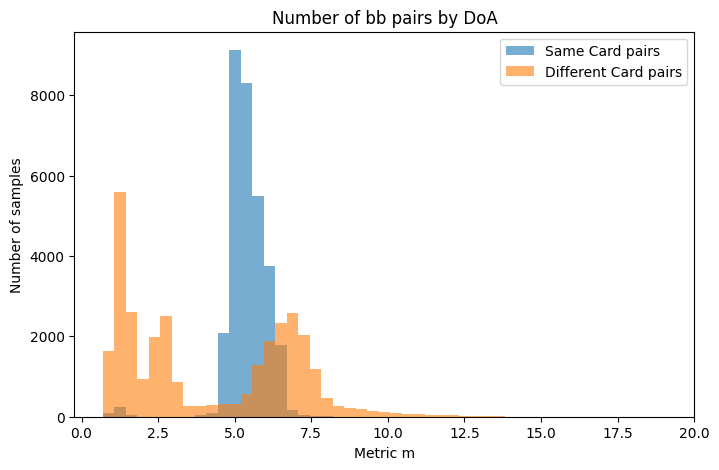


Plotting ePDFs


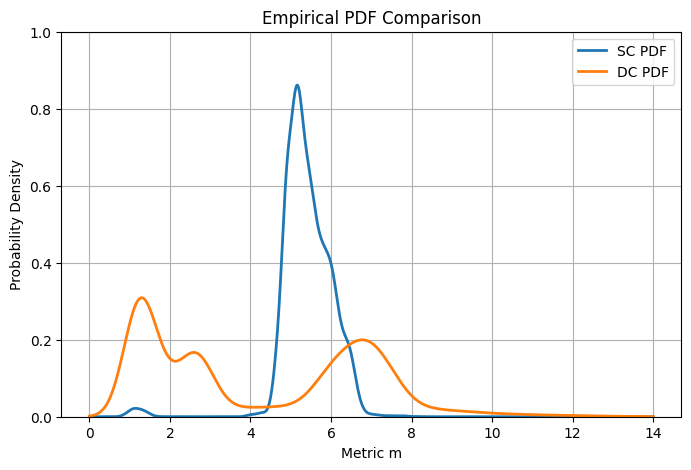


Extracting metric ranges
Match interval
conf=0.05 : 4.50 - 6.73
conf=0.10 : 4.57 - 6.63
conf=0.15 : 4.62 - 6.53
conf=0.20 : 4.67 - 6.40
conf=0.25 : 4.69 - 6.25
conf=0.30 : 4.72 - 6.17
conf=0.35 : 4.75 - 6.10
conf=0.40 : 4.78 - 6.00
conf=0.45 : 4.79 - 5.82
conf=0.50 : 4.82 - 5.68
conf=0.55 : 4.85 - 5.59
conf=0.60 : 4.88 - 5.52
conf=0.65 : 4.90 - 5.45
conf=0.70 : 4.95 - 5.38
conf=0.75 : 5.00 - 5.33
conf=0.80 : 5.06 - 5.28
conf=0.85 : 5.13 - 5.21
conf=0.90 : NOT FOUND
conf=0.95 : NOT FOUND


In [28]:
evaluate_metric_pipeline(metric = metric_DoA)